In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['axes.titlesize'] = 12

# Путь работает при запуске как из папки new, так и из корня проекта.
CSV_PATH = next((p for p in [Path('tested.csv'), Path('new/tested.csv')] if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError('Файл tested.csv не найден')

df = pd.read_csv(CSV_PATH)
print(f'Размер: {df.shape[0]} строк × {df.shape[1]} столбцов')
display(df.head())

Размер: 418 строк × 12 столбцов


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [14]:
analysis_df = df.copy()
analysis_df['FamilySize'] = analysis_df['SibSp'] + analysis_df['Parch'] + 1
analysis_df['MissingStatus'] = np.where(
    analysis_df[df.columns].isna().any(axis=1),
    'Есть пропуски',
    'Нет пропусков'
)

rows_with_missing = analysis_df[analysis_df['MissingStatus'] == 'Есть пропуски'].copy()
complete_rows = analysis_df[analysis_df['MissingStatus'] == 'Нет пропусков'].copy()

sample_summary = pd.DataFrame({
    'Группа': ['Есть пропуски', 'Нет пропусков', 'Вся выборка'],
    'Количество строк': [len(rows_with_missing), len(complete_rows), len(analysis_df)],
    'Доля, %': [
        len(rows_with_missing) / len(analysis_df) * 100,
        len(complete_rows) / len(analysis_df) * 100,
        100
    ]
})
sample_summary['Доля, %'] = sample_summary['Доля, %'].round(1)
display(sample_summary)

,Группа,Количество строк,"Доля, %"
0,Есть пропуски,331,79.2
1,Нет пропусков,87,20.8
2,Вся выборка,418,100.0


In [15]:
missing_columns = df.columns[df.isna().any()].tolist()
missing_mask = df[missing_columns].isna()

def get_missing_pattern(row):
    columns = [column for column in missing_columns if row[column]]
    return ' + '.join(columns) if columns else 'Нет пропусков'

analysis_df['MissingPattern'] = missing_mask.apply(get_missing_pattern, axis=1)
pattern_counts = analysis_df['MissingPattern'].value_counts()

intersection_table = pattern_counts.rename_axis('Пересечение').reset_index(name='Количество')
intersection_table['Доля, %'] = (intersection_table['Количество'] / len(df) * 100).round(1)
display(intersection_table)

print('Примеры строк с пропусками:')
display(rows_with_missing[['PassengerId'] + missing_columns].head())
print('Примеры полностью заполненных строк:')
display(complete_rows.head())

,Пересечение,Количество,"Доля, %"
0,Cabin,244,58.4
1,Нет пропусков,87,20.8
2,Age + Cabin,82,19.6
3,Age,4,1.0
4,Fare + Cabin,1,0.2


Примеры строк с пропусками:


,PassengerId,Age,Fare,Cabin
0,892,34.5,7.8292,NaN
1,893,47.0,7.0000,NaN
2,894,62.0,9.6875,NaN
3,895,27.0,8.6625,NaN
4,896,22.0,12.2875,NaN


Примеры полностью заполненных строк:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,MissingStatus
12,904,1,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23.0,1,0,21228,82.2667,B45,S,2,Нет пропусков
14,906,1,1,"Chaffee, Mrs. Herbert Fuller (Carrie Constance...",female,47.0,1,0,W.E.P. 5734,61.1750,E31,S,2,Нет пропусков
24,916,1,1,"Ryerson, Mrs. Arthur Larned (Emily Maria Borie)",female,48.0,1,3,PC 17608,262.3750,B57 B59 B63 B66,C,5,Нет пропусков
26,918,1,1,"Ostby, Miss. Helene Ragnhild",female,22.0,0,1,113509,61.9792,B36,C,2,Нет пропусков
28,920,0,1,"Brady, Mr. John Bertram",male,41.0,0,0,113054,30.5000,A21,S,1,Нет пропусков


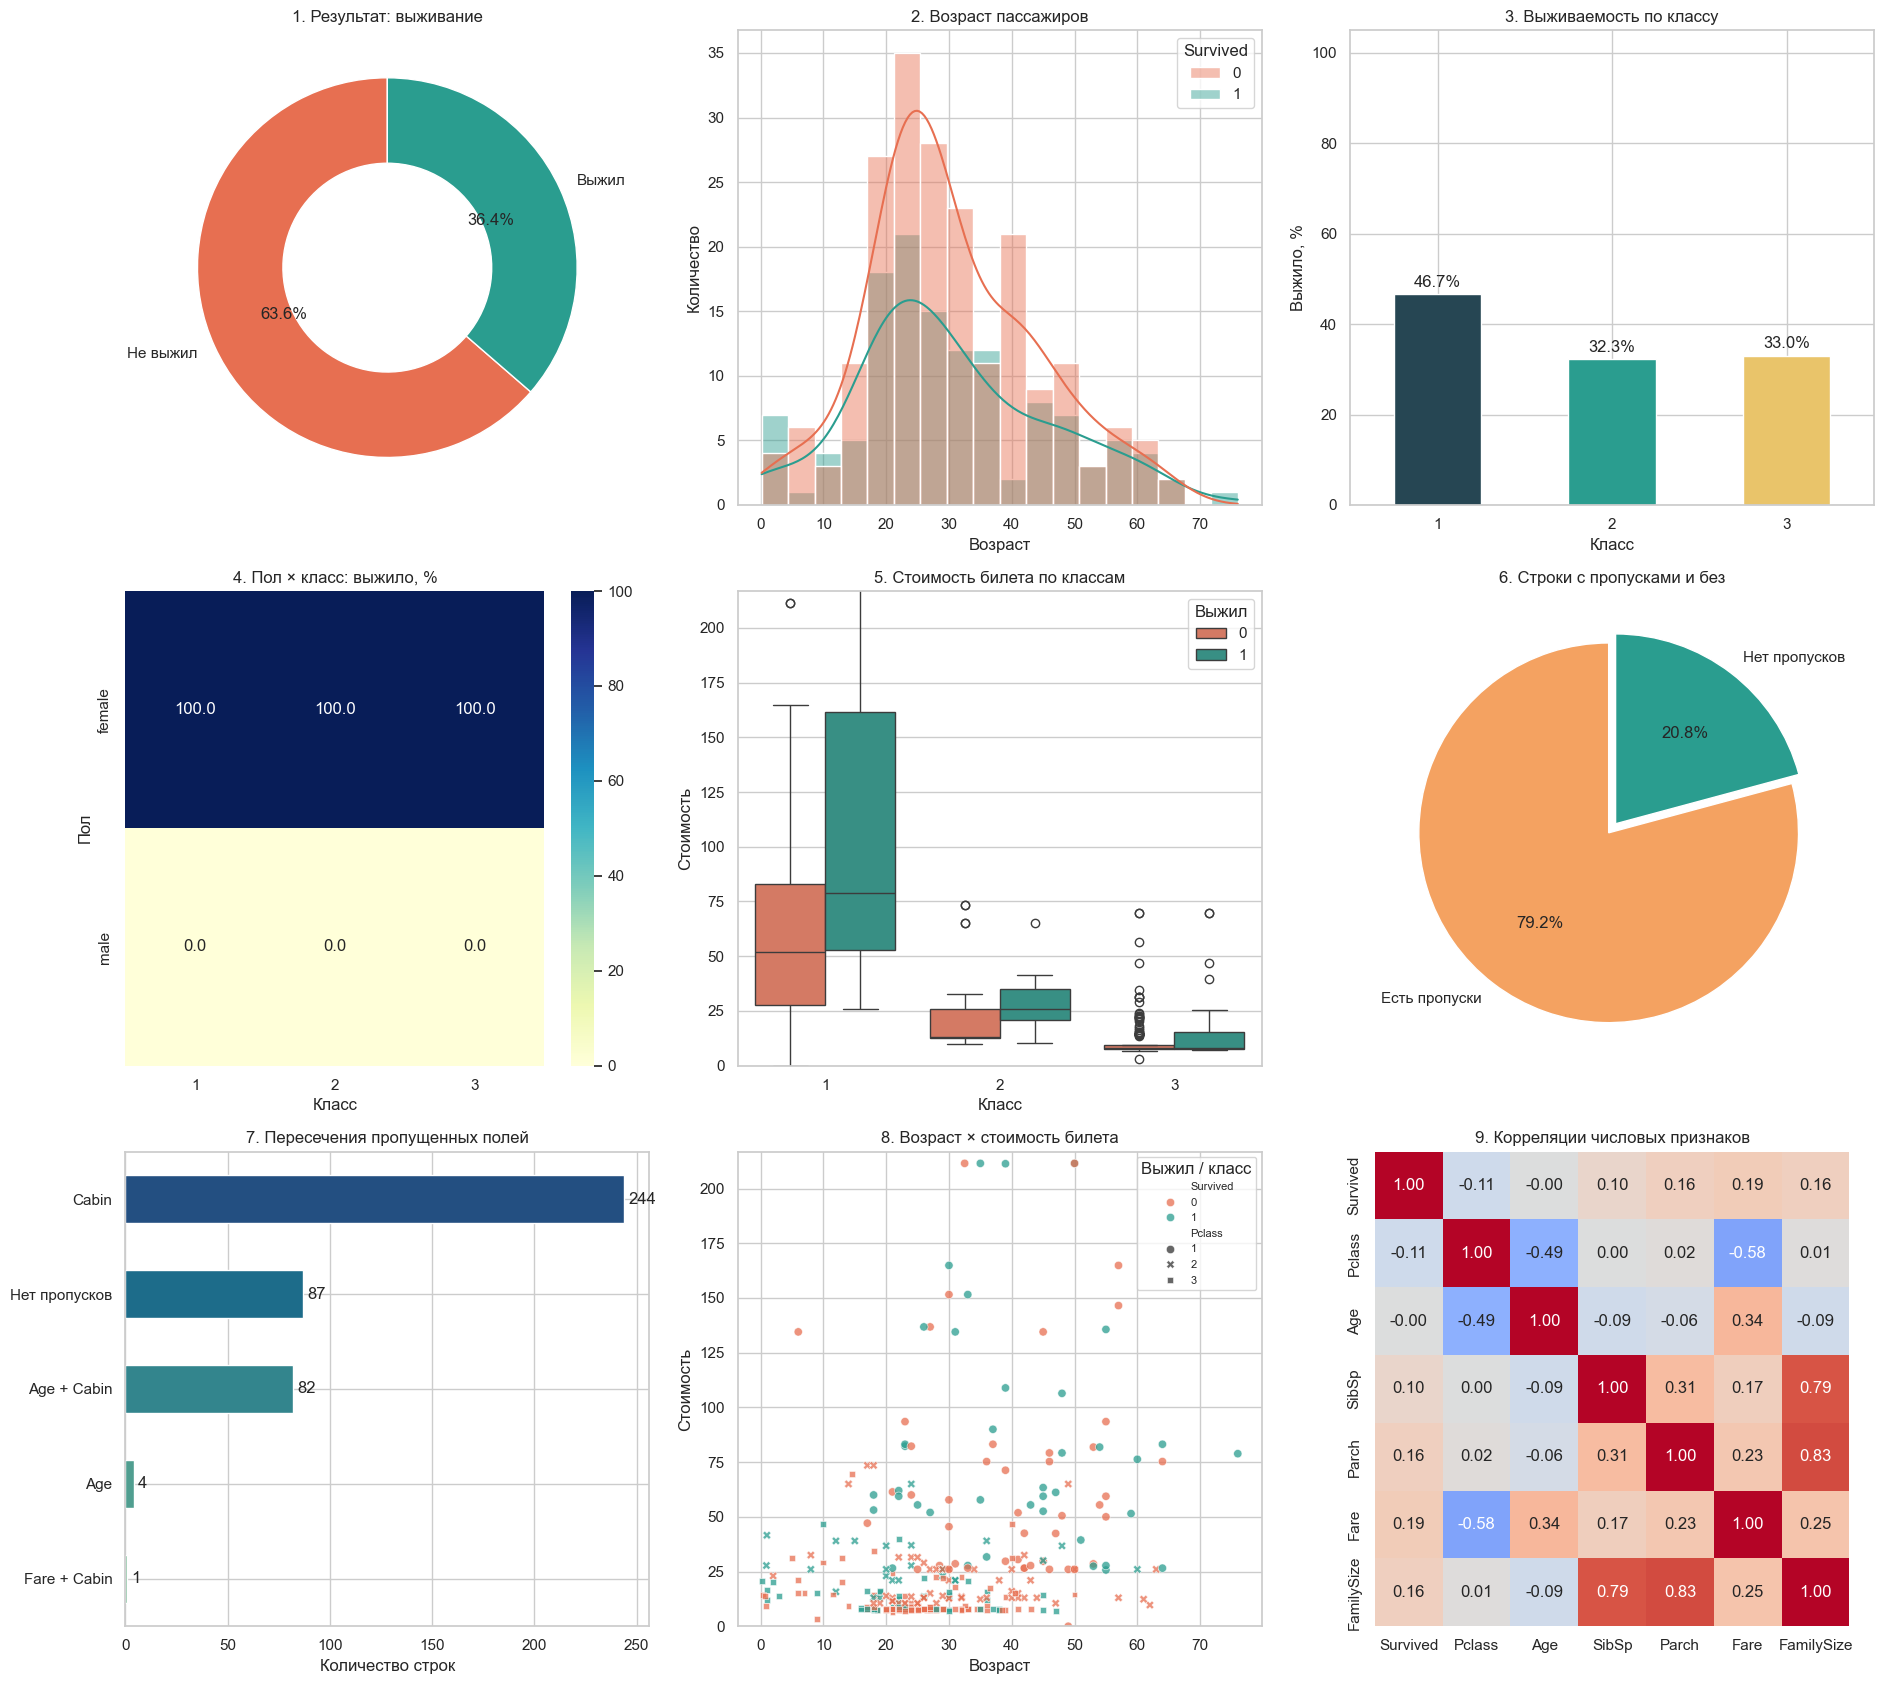

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(19, 17))

# 1. Целевое пространство: доля выживших — кольцевая диаграмма
survival = df['Survived'].value_counts().sort_index()
axes[0, 0].pie(
    survival, labels=['Не выжил', 'Выжил'], autopct='%1.1f%%',
    startangle=90, colors=['#e76f51', '#2a9d8f'],
    wedgeprops={'width': 0.45, 'edgecolor': 'white'}
)
axes[0, 0].set_title('1. Результат: выживание')

# 2. Возрастное пространство: распределение возраста — гистограмма
sns.histplot(
    data=df, x='Age', hue='Survived', bins=18, kde=True,
    palette={0: '#e76f51', 1: '#2a9d8f'}, alpha=0.45, ax=axes[0, 1]
)
axes[0, 1].set(title='2. Возраст пассажиров', xlabel='Возраст', ylabel='Количество')

# 3. Классовое пространство: процент выживших — столбцы
class_rate = df.groupby('Pclass')['Survived'].mean().mul(100)
class_rate.plot.bar(ax=axes[0, 2], color=['#264653', '#2a9d8f', '#e9c46a'], rot=0)
axes[0, 2].set(title='3. Выживаемость по классу', xlabel='Класс', ylabel='Выжило, %', ylim=(0, 105))
axes[0, 2].bar_label(axes[0, 2].containers[0], fmt='%.1f%%', padding=3)

# 4. Пол × класс: пересечение двух категорий — тепловая карта
sex_class = df.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean').mul(100)
sns.heatmap(sex_class, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=100, ax=axes[1, 0])
axes[1, 0].set(title='4. Пол × класс: выжило, %', xlabel='Класс', ylabel='Пол')

# 5. Пространство стоимости: разброс цены — коробчатая диаграмма
sns.boxplot(data=df, x='Pclass', y='Fare', hue='Survived', palette=['#e76f51', '#2a9d8f'], ax=axes[1, 1])
axes[1, 1].set_ylim(0, df['Fare'].quantile(0.97))
axes[1, 1].set(title='5. Стоимость билета по классам', xlabel='Класс', ylabel='Стоимость')
axes[1, 1].legend(title='Выжил')

# 6. Пространство качества данных: есть ли пропуски — круговая диаграмма
missing_groups = analysis_df['MissingStatus'].value_counts()
axes[1, 2].pie(
    missing_groups, labels=missing_groups.index, autopct='%1.1f%%',
    startangle=90, colors=['#f4a261', '#2a9d8f'], explode=[0.03] * len(missing_groups)
)
axes[1, 2].set_title('6. Строки с пропусками и без')

# 7. Пересечения пропусков — горизонтальные столбцы
pattern_plot = pattern_counts.sort_values()
pattern_plot.plot.barh(ax=axes[2, 0], color=sns.color_palette('crest', len(pattern_plot)))
axes[2, 0].set(title='7. Пересечения пропущенных полей', xlabel='Количество строк', ylabel='')
axes[2, 0].bar_label(axes[2, 0].containers[0], padding=3)

# 8. Возраст × стоимость: совместное пространство — диаграмма рассеяния
sns.scatterplot(
    data=df, x='Age', y='Fare', hue='Survived', style='Pclass',
    palette={0: '#e76f51', 1: '#2a9d8f'}, alpha=0.75, ax=axes[2, 1]
)
axes[2, 1].set_ylim(0, df['Fare'].quantile(0.97))
axes[2, 1].set(title='8. Возраст × стоимость билета', xlabel='Возраст', ylabel='Стоимость')
axes[2, 1].legend(title='Выжил / класс', fontsize=8)

# 9. Числовое пространство: общие связи — корреляционная карта
corr_columns = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']
corr = analysis_df[corr_columns].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar=False, ax=axes[2, 2])
axes[2, 2].set_title('9. Корреляции числовых признаков')

plt.tight_layout()
plt.show()

In [18]:
print(f"• Строк с пропусками: {len(rows_with_missing)} из {len(df)} ({len(rows_with_missing) / len(df):.1%}).")
print(f"• Полностью заполненных строк: {len(complete_rows)} из {len(df)} ({len(complete_rows) / len(df):.1%}).")
print(f"• Самое частое пересечение: «{pattern_counts.index[0]}» — {pattern_counts.iloc[0]} строк.")
print(f"• Общая доля выживших: {df['Survived'].mean():.1%}.")

sex_rate = df.groupby('Sex')['Survived'].mean()

• Строк с пропусками: 331 из 418 (79.2%).
• Полностью заполненных строк: 87 из 418 (20.8%).
• Самое частое пересечение: «Cabin» — 244 строк.
• Общая доля выживших: 36.4%.
